In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn statsmodels

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm

red = pd.read_csv("winequality-red.csv", sep=";")
white = pd.read_csv("winequality-white.csv", sep=";")

df = pd.concat([red, white], ignore_index=True)

print("Total samples:", len(df))

columns = ["alcohol", "volatile acidity", "residual sugar"]

for col in columns:
    print("\nAttribute:", col)
    print("Mean:", df[col].mean())
    print("Median:", df[col].median())
    print("Mode:", df[col].mode()[0])
    print("Standard Deviation:", df[col].std())
    print("Skewness:", df[col].skew())
    print("Coefficient of Variation:",
          df[col].std() / df[col].mean() * 100)

correlation = df["alcohol"].corr(df["quality"])
print("\nAlcohol-Quality Correlation:", correlation)

Total samples: 6497

Attribute: alcohol
Mean: 10.491800831152839
Median: 10.3
Mode: 9.5
Standard Deviation: 1.192711748870997
Skewness: 0.565717729098518
Coefficient of Variation: 11.368036508370718

Attribute: volatile acidity
Mean: 0.3396659996921656
Median: 0.29
Mode: 0.28
Standard Deviation: 0.1646364740846772
Skewness: 1.4950965423685545
Coefficient of Variation: 48.47010717407243

Attribute: residual sugar
Mean: 5.443235339387409
Median: 3.0
Mode: 2.0
Standard Deviation: 4.757803743147445
Skewness: 1.4354042627889907
Coefficient of Variation: 87.40764355198532

Alcohol-Quality Correlation: 0.44431852000765404


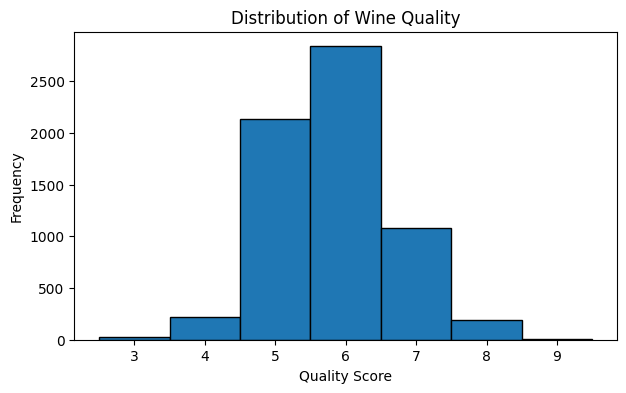

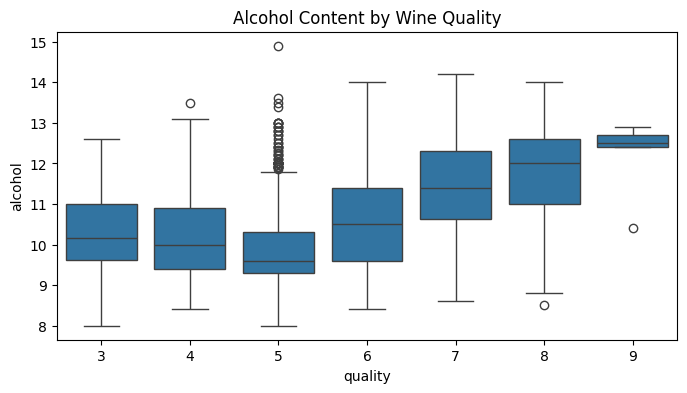

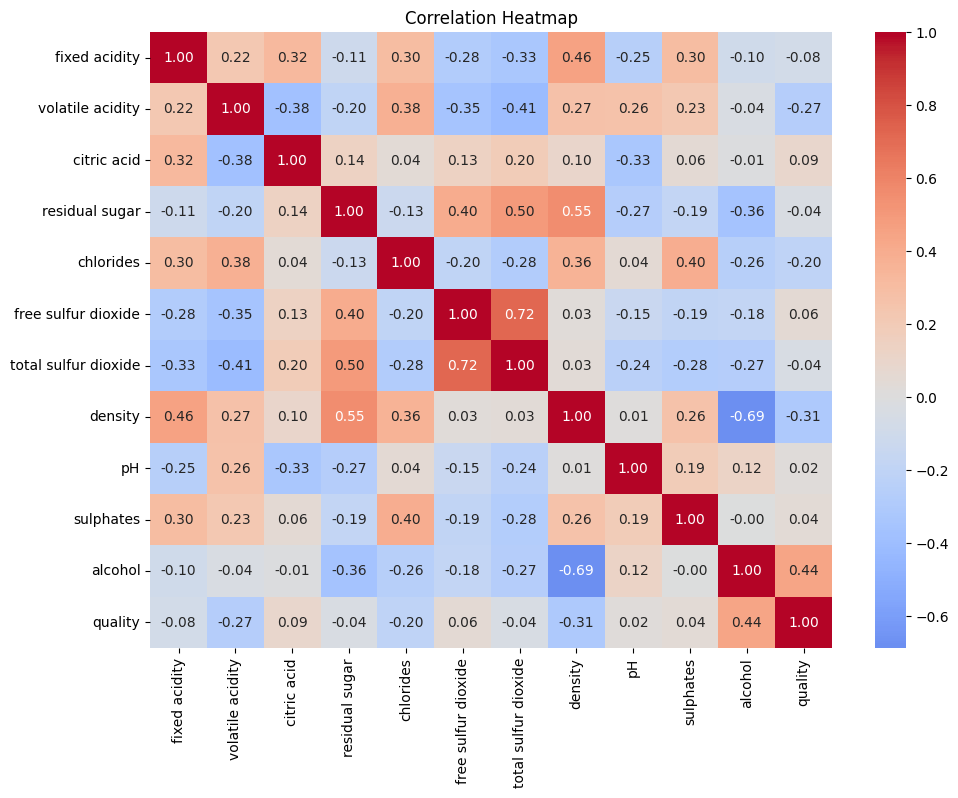

Two attributes most strongly associated with quality:
alcohol    0.444319
density   -0.305858
Name: quality, dtype: float64


In [7]:
plt.figure(figsize=(7, 4))
plt.hist(df["quality"], bins=np.arange(2.5, 10.5, 1), edgecolor="black")
plt.xlabel("Quality Score")
plt.ylabel("Frequency")
plt.title("Distribution of Wine Quality")
plt.show()

plt.figure(figsize=(8, 4))
sns.boxplot(data=df, x="quality", y="alcohol")
plt.title("Alcohol Content by Wine Quality")
plt.show()

corr = df.corr(numeric_only=True)

plt.figure(figsize=(11, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.show()

quality_corr = corr["quality"].drop("quality")
top_two = quality_corr.reindex(
    quality_corr.abs().sort_values(ascending=False).index
).head(2)

print("Two attributes most strongly associated with quality:")
print(top_two)

MAE: 0.566
MSE: 0.547
RMSE: 0.739
R2 Score: 0.26


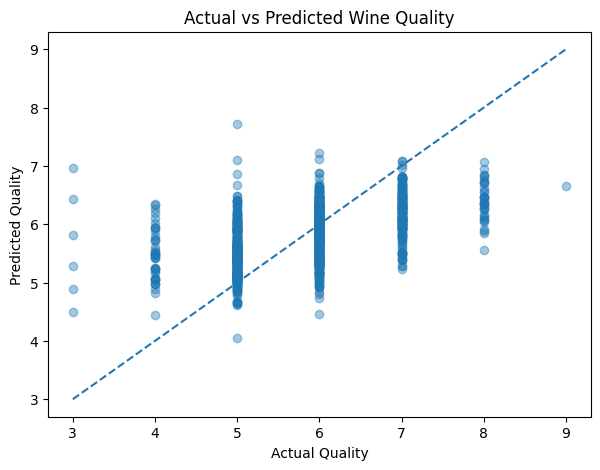

In [8]:
X = df.drop("quality", axis=1)
y = df["quality"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

predictions = model.predict(X_test)

mae = mean_absolute_error(y_test, predictions)
mse = mean_squared_error(y_test, predictions)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, predictions)

print("MAE:", round(mae, 3))
print("MSE:", round(mse, 3))
print("RMSE:", round(rmse, 3))
print("R2 Score:", round(r2, 3))

plt.figure(figsize=(7, 5))
plt.scatter(y_test, predictions, alpha=0.4)

lower = min(y_test.min(), predictions.min())
upper = max(y_test.max(), predictions.max())

plt.plot([lower, upper], [lower, upper], "--")
plt.xlabel("Actual Quality")
plt.ylabel("Predicted Quality")
plt.title("Actual vs Predicted Wine Quality")
plt.show()

In [9]:
scaler_X = StandardScaler()
scaler_y = StandardScaler()

X_scaled = scaler_X.fit_transform(X_train)
y_scaled = scaler_y.fit_transform(
    y_train.to_numpy().reshape(-1, 1)
).ravel()

std_model = LinearRegression()
std_model.fit(X_scaled, y_scaled)

coefficients = pd.Series(
    std_model.coef_, index=X.columns
).sort_values(key=lambda x: x.abs(), ascending=False)

print("Two strongest standardized predictors:")
print(coefficients.head(2))

X_vif = sm.add_constant(X_train)

vif = pd.DataFrame({
    "Attribute": X_train.columns,
    "VIF": [
        variance_inflation_factor(X_vif.values, i)
        for i in range(1, X_vif.shape[1])
    ]
})

print("\nVariance Inflation Factors:")
print(vif.sort_values("VIF", ascending=False))

Two strongest standardized predictors:
alcohol           0.367843
residual sugar    0.251408
dtype: float64

Variance Inflation Factors:
               Attribute        VIF
7                density  15.505703
3         residual sugar   7.196362
0          fixed acidity   4.741209
10               alcohol   4.616211
6   total sulfur dioxide   2.961042
8                     pH   2.470529
5    free sulfur dioxide   2.159138
1       volatile acidity   1.936238
4              chlorides   1.645719
2            citric acid   1.613585
9              sulphates   1.544265
